<a href="https://colab.research.google.com/github/Yu-hsiu/QuaCCAToo/blob/main/%E6%8A%80%E8%A1%93%E6%89%8B%E5%86%8A%E5%AF%A6%E4%BD%9C%E6%B8%AC%E8%A9%A6V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# KWANTEACH 技術手冊 v1.2.0 摘要 × QuaCCAToo 實作(安裝格,先執行)
# 對應簡報:technical-manual_v1.2.0_摘要與QuaCCAToo實作.pptx
!pip install -q git+https://github.com/Yu-hsiu/QuaCCAToo
import quaccatoo, qutip
print('quaccatoo', quaccatoo.__version__, '| qutip', qutip.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
quaccatoo 1.3.0 | qutip 5.3.1


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit import Model
from qutip import basis
from quaccatoo import (NV, PMR, Analysis, ExpData, Hahn, PulsedSim, Rabi, RabiModel,
                       Ramsey, fit_exp_decay, plot_energy_B0)

## 第 4–5 章:由能階直接得到 ODMR 頻率與 Zeeman 斜率

不需要跑時間演化,NV 物件建好就有能階與共振頻率。掃磁場做線性擬合,就是手冊第 5 章的資料處理。

- `N=0` 表示不含氮核自旋,只看精細結構;`E` 是應變參數(MHz),`theta` 是磁場與 NV 軸夾角
- 預期:γ = 28.03 MHz/mT、D = 2870.0 MHz;零場應變分裂 2E = 2.00 MHz;3 mT、81° 時 f = 2860.4 與 2886.8 MHz
- 四個晶向:各算一個 theta 後把譜線疊加

[ch5] gamma = 28.025 MHz/mT, D = 2870.0 MHz
[ch4] zero-field strain splitting = 2.00 MHz (2E)
[ch5] B=3 mT, theta=81 deg: f- = 2860.4, f+ = 2886.8 MHz


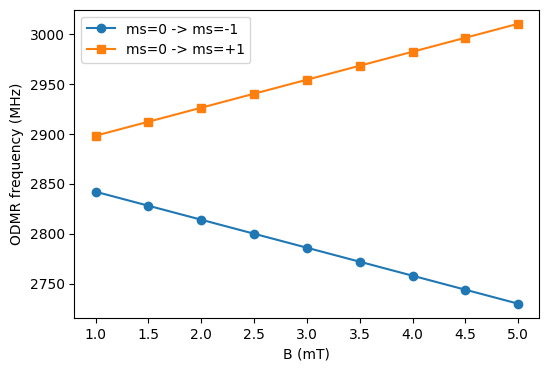

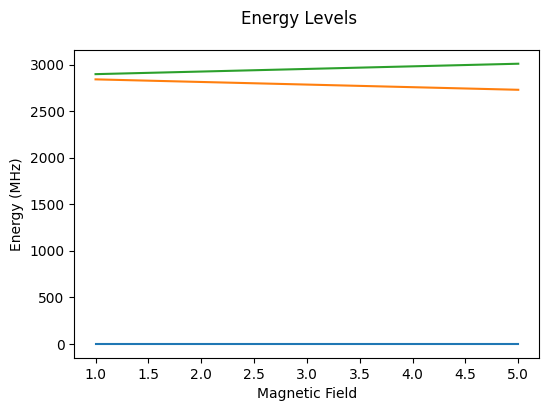

In [ ]:
# ch5: sweep B along the NV axis, fit D and gamma
B = np.linspace(1, 5, 9)                # mT
f = np.array([NV(B0=b, N=0).MW_freqs for b in B])
gamma, D = np.polyfit(B, f[:, 1], 1)
print(f'[ch5] gamma = {gamma:.3f} MHz/mT, D = {D:.1f} MHz')
assert abs(gamma - 28.03) < 0.1 and abs(D - 2870) < 1

# ch4: strain splitting 2E at zero field
split = abs(np.diff(NV(B0=0, N=0, E=1.0).MW_freqs)[0])   # level order of the pair is platform dependent
print(f'[ch4] zero-field strain splitting = {split:.2f} MHz (2E)')
assert abs(split - 2.0) < 0.01

# ch5: off-axis field (quadratic term)
off_axis = NV(B0=3, N=0, theta=81).MW_freqs
print(f'[ch5] B=3 mT, theta=81 deg: f- = {off_axis[0]:.1f}, f+ = {off_axis[1]:.1f} MHz')

plt.figure(figsize=(6, 4))
plt.plot(B, f[:, 0], 'o-', label='ms=0 -> ms=-1')
plt.plot(B, f[:, 1], 's-', label='ms=0 -> ms=+1')
plt.xlabel('B (mT)'); plt.ylabel('ODMR frequency (MHz)'); plt.legend(); plt.show()

# energy levels versus field
plot_energy_B0(B0=B, H0=[NV(B0=b, N=0).H0 for b in B])

## 第 6 章:低功率脈衝 ODMR 解析三條 14N 超精細線

PMR 是脈衝式 ODMR:固定脈衝長度、掃頻率。w1 要比 2.16 MHz 小很多才分得開三條線,對應手冊說的低 RF 功率。

- 這是脈衝 ODMR,手冊第 4 章是連續波;譜線位置相同,線形不同
- 長脈衝要調高 `nsteps`,否則積分器報錯
- 預期:三個谷間距約 2.14 MHz(套件內建常數;手冊量到 2.163 MHz)
- **此格在 Colab 需數分鐘**;改 w1 = 1、3、10 可重現功率展寬(圖 79–80)

[ch6] hyperfine dips at [2783.77 2785.93 2788.09] MHz, spacing = 2.16 MHz


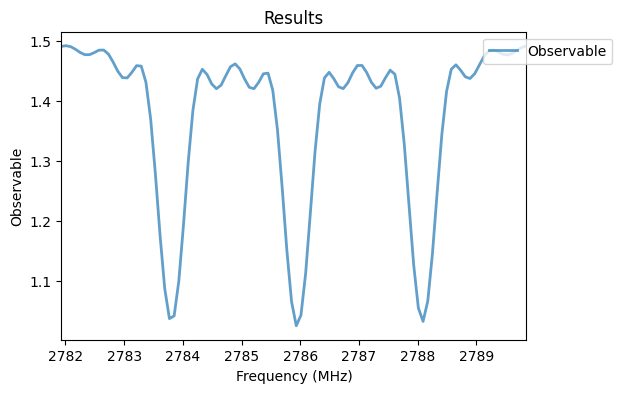

In [ ]:
nv14 = NV(B0=3, N=14)       # with 14N nuclear spin
w1 = 0.3                    # MHz, low power
f0 = nv14.MW_freqs[0]       # ms=0 -> ms=-1

odmr = PMR(
    frequencies=np.arange(f0 - 4, f0 + 4, 0.08),
    system=nv14,
    pulse_duration=1 / 2 / w1,
    h1=w1 * nv14.MW_h1,
    options={'nsteps': 100000},
)
odmr.run()
Analysis(odmr).plot_results()

freqs, signal = np.asarray(odmr.variable), np.asarray(odmr.results)
minima = [i for i in range(1, len(signal) - 1) if signal[i] < min(signal[i - 1], signal[i + 1])]
main = np.sort(freqs[sorted(minima, key=lambda i: signal[i])[:3]])
spacing = float(np.mean(np.diff(main)))
print(f'[ch6] hyperfine dips at {np.round(main, 2)} MHz, spacing = {spacing:.2f} MHz')
assert abs(spacing - 2.16) < 0.15

## 第 14–15 章:Rabi 定出 π 脈衝,Ramsey 看超精細拍頻

Rabi 的 w1 設成讓 π 脈衝等於手冊量到的 119 ns。Ramsey 用含 14N 的系統,FFT 會出現約 2 MHz 的峰,對應手冊圖 141 的功率譜。

- 預期:擬合 Tπ = 119.0 ns;FFT 主峰在 2.0 MHz(3 µs 視窗的解析度約 0.3 MHz)
- 改 w1 重現功率相依(圖 130);`f_pulse` 加 3.5 MHz 重現失諧效應(圖 131)
- 要看到 T2* 衰減包絡,需在 NV 加 c_ops 退相干項

[ch14] fitted T_pi = 119.0 ns


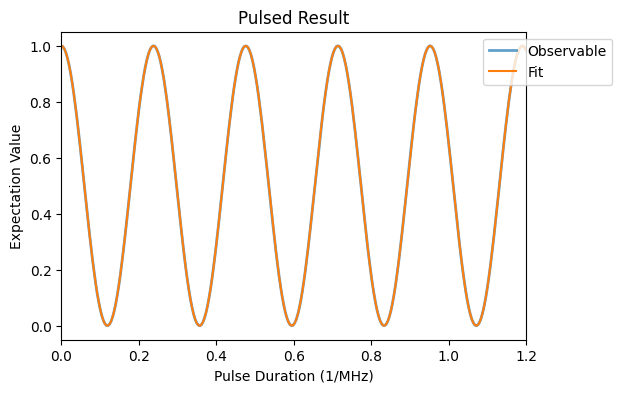

In [ ]:
# ch14: Rabi
nv = NV(B0=3, N=0)
w1 = 1 / 2 / 0.119          # pi pulse 119 ns
rabi = Rabi(
    pulse_duration=np.linspace(0, 1.2, 300),
    system=nv, h1=w1 * nv.MW_h1,
    pulse_params={'f_pulse': nv.MW_freqs[0]})
rabi.run()
ana = Analysis(rabi)
ana.run_fit(fit_model=RabiModel())
ana.plot_fit()
t_pi = ana.fit_params.best_values['Tpi']
print(f'[ch14] fitted T_pi = {t_pi * 1e3:.1f} ns')
assert abs(t_pi - 0.119) < 0.005

[ch15] Ramsey FFT peaks below 6 MHz = [2.01] MHz


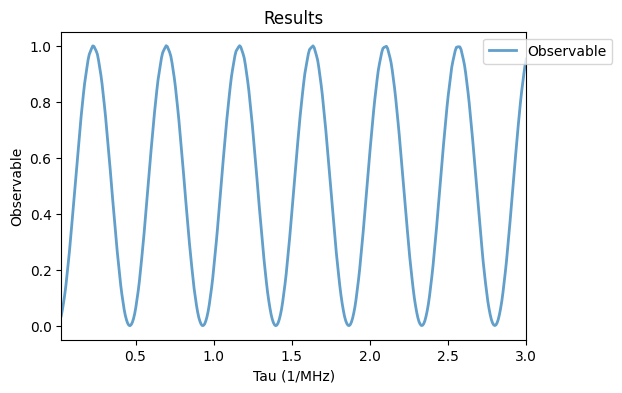

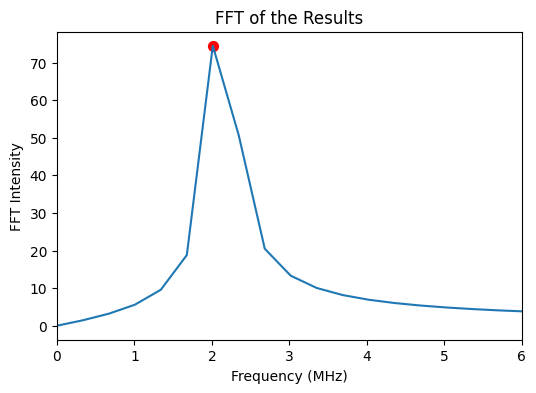

In [ ]:
# ch15: Ramsey + FFT
nv14 = NV(B0=3, N=14); w1 = 20
ram = Ramsey(
    free_duration=np.linspace(1 / 2 / w1, 3, 400),
    system=nv14, pi_pulse_duration=1 / 2 / w1,
    h1=w1 * nv14.MW_h1,
    pulse_params={'f_pulse': nv14.MW_freqs[0]})
ram.run()
ana = Analysis(ram)
ana.plot_results()
ana.run_FFT()
peaks = np.asarray(ana.get_peaks_FFT(), dtype=float)
ana.plot_FFT(freq_lim=[0, 6])
print(f'[ch15] Ramsey FFT peaks below 6 MHz = {np.round(peaks[peaks < 6], 2)} MHz')
assert np.any(np.abs(peaks - 2.15) < 0.2)

## 第 12、16 章:Hahn echo 內建,T1 用 PulsedSim 自組序列

Hahn 是內建類別。T1 沒有內建序列,因為套件沒有雷射;做法是直接從 ms=0 出發,用 c_ops 給弛豫率,自由演化後量族群。這是現象學模型。

- 初始態預設就是 ms=0,等同雷射極化後的狀態
- 預期:無自旋浴時回波維持 0.998;T1 曲線收斂到 0.333,即三能階均分
- 自組序列要先設 `time_steps`,否則含 c_ops 的自由演化會報錯
- 13C 復甦:用 `nv.add_spin` 加 13C(見套件教學 04)

[ch16] Hahn echo without bath: mean 0.998, ptp 0.005
[ch12] T1 fit: Tc = 1.061 us, plateau = 0.333


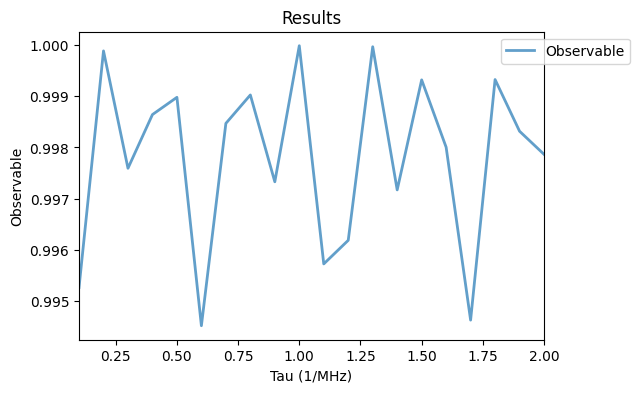

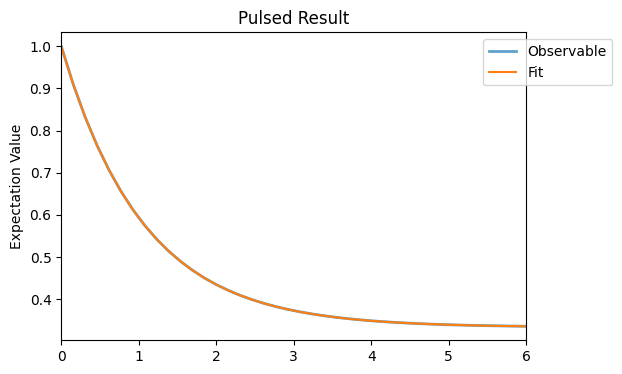

In [ ]:
# ch16: Hahn echo
nv = NV(B0=3, N=0); w1 = 10
echo = Hahn(
    free_duration=np.linspace(0.1, 2, 20),
    system=nv, pi_pulse_duration=1 / 2 / w1,
    h1=w1 * nv.MW_h1,
    pulse_params={'f_pulse': nv.MW_freqs[0]})
echo.run()
Analysis(echo).plot_results()
print(f'[ch16] Hahn echo without bath: mean {np.mean(echo.results):.3f}, ptp {np.ptp(echo.results):.3f}')

# ch12: phenomenological T1
rate = 0.05
jumps = [np.sqrt(rate) * basis(3, i) * basis(3, j).dag()
         for i in range(3) for j in range(3) if i != j]
relax = NV(B0=3, N=0, c_ops=jumps)

def dark_time(tau):
    seq = PulsedSim(relax)
    seq.time_steps = 100    # free evolution with c_ops needs a time grid
    seq.add_free_evolution(duration=tau)
    return seq.rho

t1 = PulsedSim(relax)
t1.run(variable=np.linspace(0, 6, 40), sequence=dark_time)
ana = Analysis(t1)
ana.run_fit(fit_model=Model(fit_exp_decay), guess={'amp': 0.6, 'offset': 0.33, 'Tc': 1})
ana.plot_fit()
best = ana.fit_params.best_values
print(f'[ch12] T1 fit: Tc = {best["Tc"]:.3f} us, plateau = {best["offset"]:.3f}')
assert abs(best['offset'] - 1 / 3) < 0.02

## 接上真實數據:把量測檔和模擬疊在一起

用 ExpData 讀入量測檔,再用 compare_with 和模擬比對,得到相關係數。簡報上的檔名是示意;這裡改用 repo 內附的真實 NV Rabi 量測 `Ex02_NV_rabi.dat`(套件教學 02 的設定:15N、38.4 mT、w1 = 16.72 MHz),所以此格可以實際執行。

- 換成 KWANTEACH 匯出檔時,需依實際格式調整欄位與單位
- ExpData 提供 offset、rescale、多項式基線校正;ODMR 數據同樣可讀入後用 fit_lorentz 擬合

Pearson r = LinregressResult(slope=np.float64(2.5895433124831997), intercept=np.float64(-2.045360603774133), rvalue=np.float64(0.9872724331132603), pvalue=np.float64(5.4508300109252925e-40), stderr=np.float64(0.060209767213130316), intercept_stderr=np.float64(0.05996996938645248))


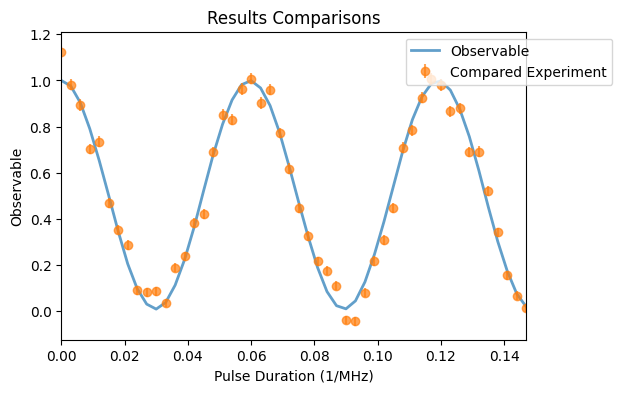

In [ ]:
!wget -q -O Ex02_NV_rabi.dat https://raw.githubusercontent.com/Yu-hsiu/QuaCCAToo/main/docs/tutorials/exp_data_tutorials/Ex02_NV_rabi.dat

exp = ExpData(
    file_path='Ex02_NV_rabi.dat',
    variable_column=0,     # pulse duration
    results_columns=1,     # PL contrast
    yerr_columns=2,
)
exp.variable *= 1e6        # s -> us

nv15 = NV(N=15, B0=38.4, units_B0='mT')
w1 = 16.72
rabi_exp = Rabi(
    pulse_duration=np.arange(0, 0.15, 3e-3),
    system=nv15, h1=w1 * nv15.MW_h1,
    pulse_params={'f_pulse': nv15.MW_freqs[0]})
rabi_exp.run()

ana = Analysis(rabi_exp)
ana.compare_with(exp)
ana.plot_comparison()
print('Pearson r =', ana.pearson)